<a href="https://colab.research.google.com/github/sejalkubal18/CSL701-CE21_Machine-Learning-Lab/blob/main/experiment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

name: Sejal Mahadev Kubal

Roll no: CE21

##Import Required Libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display graphs inside Colab
%matplotlib inline

##Load the Dataset


In [2]:
from google.colab import files

uploaded = files.upload()

Saving auto-mpg (3).csv to auto-mpg (3).csv


In [6]:
import pandas as pd

df = pd.read_csv("auto-mpg (3).csv")

# Display first 5 rows
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


##Display Dataset Information

In [7]:
print("Shape of Dataset:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Shape of Dataset:
(398, 9)

Column Names:
Index(['mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
       'acceleration', 'model year', 'origin', 'car name'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    object 
dtypes: float64(3), int64(4), object(2)
memory usage: 28.1+ KB


##Check Missing Values

In [8]:
print(df.isnull().sum())

mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64


##Remove Missing Values

In [9]:
df = df.dropna()

print("New Shape:", df.shape)

New Shape: (398, 9)



##Select Horsepower and MPG

In [10]:
X = df['horsepower'].values
Y = df['mpg'].values

print("Horsepower:")
print(X[:5])

print("\nMPG:")
print(Y[:5])

Horsepower:
['130' '165' '150' '150' '140']

MPG:
[18. 15. 18. 16. 17.]


##Exploratory Data Analysis (EDA)

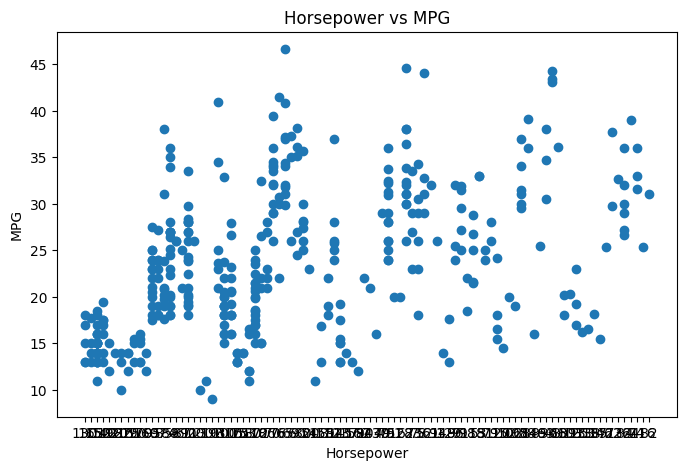

In [11]:
plt.figure(figsize=(8,5))

plt.scatter(X, Y)

plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("Horsepower vs MPG")

plt.show()

##Calculate Correlation

In [15]:
df_cleaned = df.copy()
# Replace '?' with NaN and convert 'horsepower' to numeric
df_cleaned['horsepower'] = df_cleaned['horsepower'].replace('?', np.nan).astype(float)

# Drop rows with NaN values in 'horsepower' or 'mpg' for correlation calculation
df_cleaned = df_cleaned.dropna(subset=['horsepower', 'mpg'])

correlation = df_cleaned['horsepower'].corr(df_cleaned['mpg'])

print("Correlation =", correlation)

Correlation = -0.7784267838977756


##Add Bias (Intercept)

In [16]:
X_bias = np.c_[np.ones(len(X)), X]

print(X_bias[:5])

[[1.0 '130']
 [1.0 '165']
 [1.0 '150']
 [1.0 '150']
 [1.0 '140']]


##Calculate OLS Coefficients

In [19]:
X = df_cleaned['horsepower'].values
Y = df_cleaned['mpg'].values

X_bias = np.c_[np.ones(len(X)), X]

weights = np.linalg.inv(X_bias.T @ X_bias) @ X_bias.T @ Y

print("Intercept (w0):", weights[0])
print("Slope (w1):", weights[1])

Intercept (w0): 39.9358610211705
Slope (w1): -0.15784473335365387


##Predict MPG

In [20]:
Y_pred = X_bias @ weights

print(Y_pred[:10])

[19.41604569 13.89148002 16.25915102 16.25915102 17.83759835  8.68260382
  5.21001968  5.99924335  4.42079602  9.94536168]


##Calculate Residuals

In [21]:
residuals = Y - Y_pred

print(residuals[:10])

[-1.41604569  1.10851998  1.74084898 -0.25915102 -0.83759835  6.31739618
  8.78998032  8.00075665  9.57920398  5.05463832]


##Calculate SSE

In [22]:
SSE = np.sum(residuals ** 2)

print("SSE =", SSE)

SSE = 9385.915871932419


##Calculate MSE

In [23]:
MSE = np.mean(residuals ** 2)

print("MSE =", MSE)

MSE = 23.943662938603108


##Calculate R² Score

In [24]:
SST = np.sum((Y - np.mean(Y))**2)

R2 = 1 - (SSE/SST)

print("R² =", R2)

R² = 0.6059482578894348


##Plot Regression Line

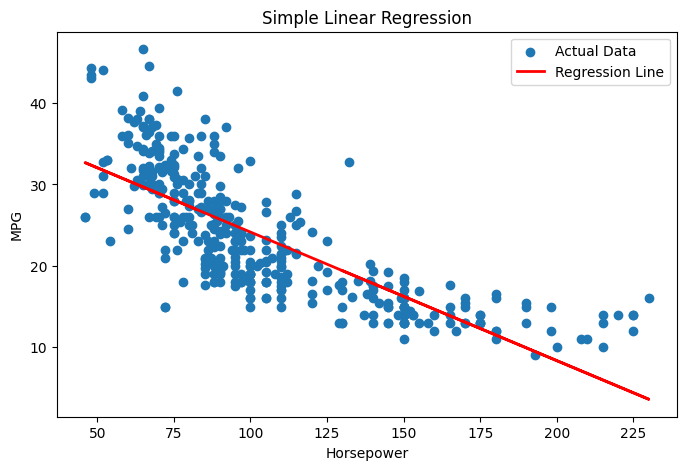

In [25]:
plt.figure(figsize=(8,5))

plt.scatter(X, Y, label="Actual Data")

plt.plot(X, Y_pred, color='red', linewidth=2, label="Regression Line")

plt.xlabel("Horsepower")
plt.ylabel("MPG")

plt.title("Simple Linear Regression")

plt.legend()

plt.show()

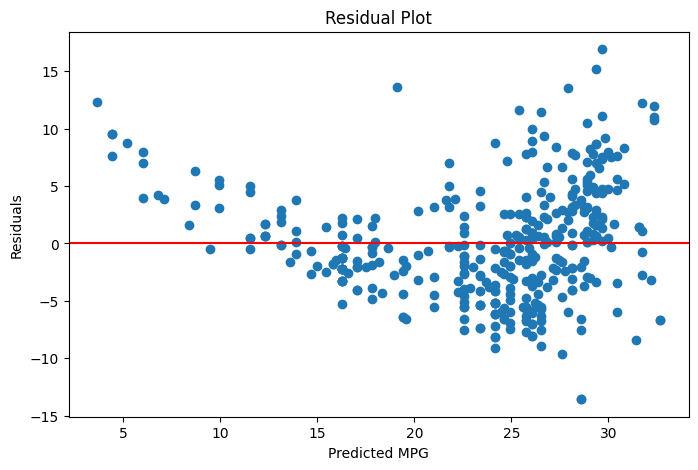

In [26]:
plt.figure(figsize=(8,5))

plt.scatter(Y_pred, residuals)

plt.axhline(y=0, color='red')

plt.xlabel("Predicted MPG")
plt.ylabel("Residuals")

plt.title("Residual Plot")

plt.show()